# **Machine Learning Project**
<span style="font-size: 23px;">**Prediction price of used car**</span><br><br>
ML-проект по решению задачи предсказания цены использованного автомобиля на основе сопутствующих признаков.

В качестве данных используется датасет с **[Kaggle](https://www.kaggle.com/)**: **[Used Car Price Prediction Dataset](https://www.kaggle.com/datasets/taeefnajib/used-car-price-prediction-dataset/data)**. Целевой переменной считается `price` (цена автомобиля).

## Гипотезы

**Г1:** Между пробегом автомобиля и его ценой (колонки `milage` и `price` соответственно) существует отрицательная корреляция.

**Проверка:** Построить диаграмму рассеяния для двух признаков и посмотреть на получившийся график с линией тренда.
<br>
<br>    
**Г2:** Наличие чистого ПТС (колонка `clean_title`) влияет на цену автомобиля, есть положительная корреляция.

**Проверка:** Закодировать признак на этапе разведочного анализа и проанализировать тепловую карту.
<br>
<br>
<br>
**Г3:** Показатель $R^2$ будет лучше, если заменить год производства автомобиля на его возраст. Возможно, начало отсчёта с 0 позволит модели улучшить показатели точности, в отличие от работы с годичной временной шкалой.

**Проверка:** Построить два пайплайна, один будет содержать столбцы с возрастом, другой - с годом производства. Сравнить критерий $R^2$ в двух случаях.
<br>
<br>
<br>
**Г4:** Логарифмирование таргета улучшит метрику $R^2$ линейной регрессии.

**Проверка:** Построить два пайплайна: один без логарифмирования таргета, другой - с логарифмированием (с использованием `TransformedTargetRegressor`) и оценить $R^2$.
<br>
<br>
<br>
**Г5:** Нахождение лучших параметров с использованием GridSearch даст прирост в метрике $R^2$ по сравнению с базовыми настройками модели.

**Проверка:** Обучение модели на стандартных настройках, затем подбор параметров. Сравнение метрик моделей.

## Импорт необходимых библиотек

In [237]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datetime import datetime

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Запишем датасет в переменную `df` и посмотрим на количество строк и столбцов:

In [238]:
df = pd.read_csv('/kaggle/input/datasets/callmejaso/used-cars/used_cars.csv')
df.shape

(4009, 12)

## EDA (Разведочный анализ данных)

Проведем первоначальный анализ датасета, посмотрим на структуру, типы данных, признаки.

In [239]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [240]:
df.dtypes

brand           object
model           object
model_year       int64
milage          object
fuel_type       object
engine          object
transmission    object
ext_col         object
int_col         object
accident        object
clean_title     object
price           object
dtype: object

In [241]:
df.isna().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

### Распределения числовых величин

Рассмотрим распределения числовых величин и построим boxplot'ы для их оценки.
После применения `dtypes` можно заметить, что большинство столбцов - это тип *object*, значит сейчас нужно корректно обработать числовые признаки. Можно использовать регулярное выражение для получения числа из колонки `price`:

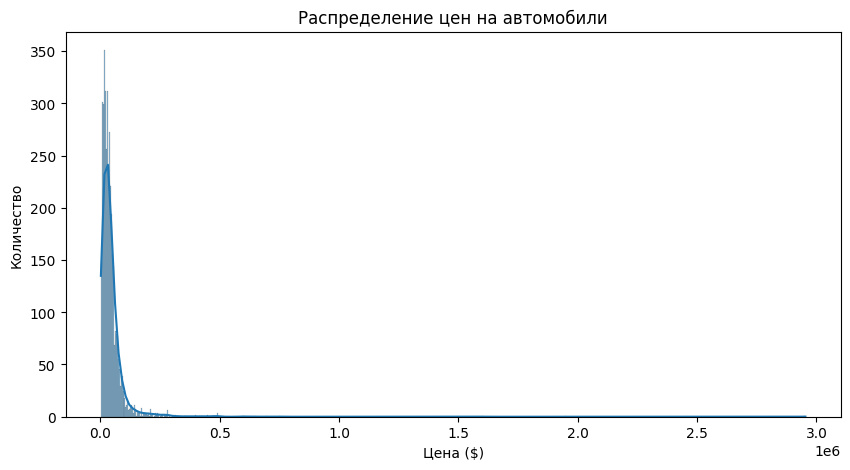

In [242]:
modern_price = df['price'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['price'] = pd.to_numeric(modern_price, errors='coerce')

plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins='auto', kde=True)
plt.title('Распределение цен на автомобили')
plt.xlabel('Цена ($)')
plt.ylabel('Количество')
plt.show()

Можно заметить "длинный хвост" у данного распределения. Попробуем провести анализ по логарифмической шкале: 

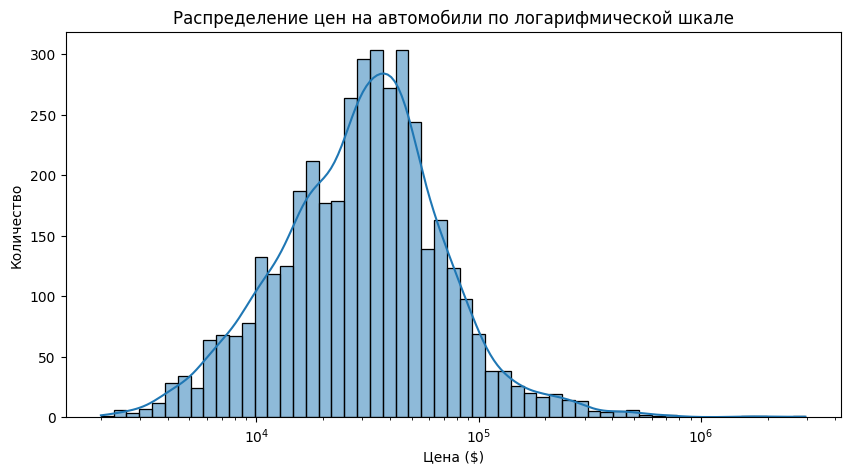

In [243]:
plt.figure(figsize=(10,5))
sns.histplot(df['price'], bins='auto', kde=True, log_scale=True)
plt.title('Распределение цен на автомобили по логарифмической шкале')
plt.xlabel('Цена ($)')
plt.ylabel('Количество')
plt.show()

Рассмотрим также распределения для величины пробега и года выпуска авто:

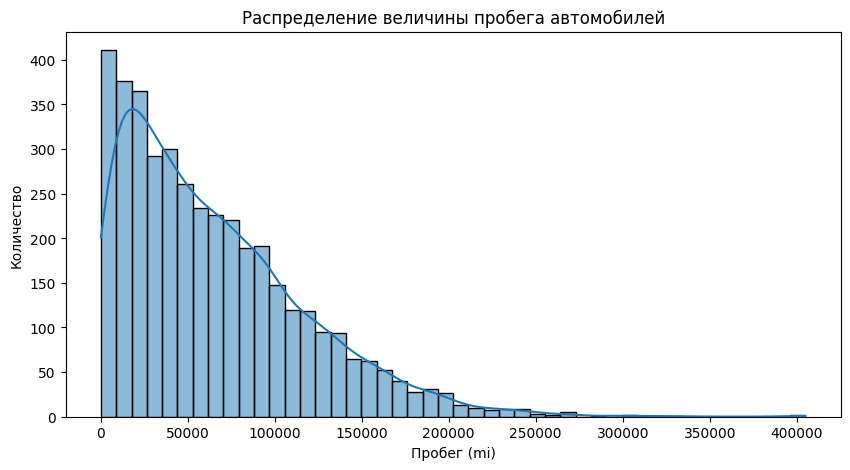

In [244]:
modern_milage = df['milage'].astype(str).str.replace(r'[^\d]', '', regex=True)
df['milage'] = pd.to_numeric(modern_milage, errors='coerce')

plt.figure(figsize=(10,5))
sns.histplot(df['milage'], bins='auto', kde=True)
plt.xlabel('Пробег (mi)')
plt.ylabel('Количество')
plt.title('Распределение величины пробега автомобилей')
plt.show()

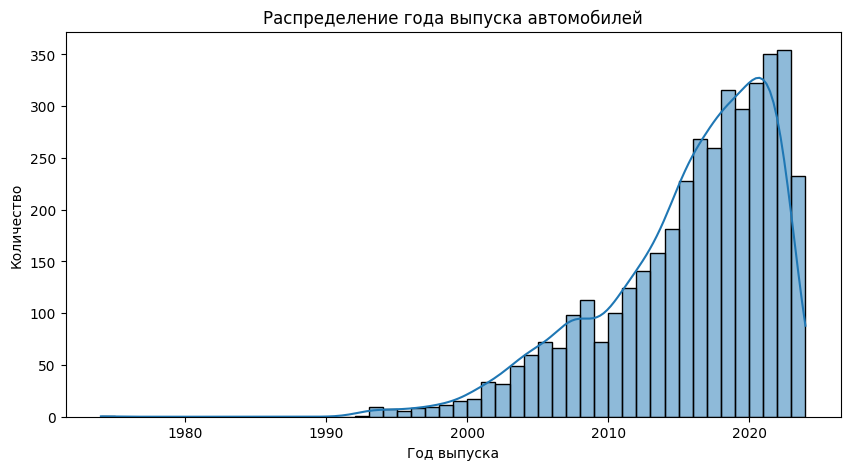

In [245]:
plt.figure(figsize=(10,5))
sns.histplot(df['model_year'], bins='auto', kde=True)
plt.title('Распределение года выпуска автомобилей')
plt.xlabel('Год выпуска')
plt.ylabel('Количество')
plt.show()

Распределение величин пробега и года выпуска имеют смещения влево и вправо соответственно. Вероятно, дело в выбросах. Проверим числовые характеристики на минимальные и максимальные значения.

In [246]:
df[['milage', 'model_year', 'price']].describe()

,milage,model_year,price
count,4009.000000,4009.000000,4.009000e+03
mean,64717.551010,2015.515590,4.455319e+04
std,52296.599459,6.104816,7.871064e+04
min,100.000000,1974.000000,2.000000e+03
25%,23044.000000,2012.000000,1.720000e+04
50%,52775.000000,2017.000000,3.100000e+04
75%,94100.000000,2020.000000,4.999000e+04
max,405000.000000,2024.000000,2.954083e+06


### Диаграммы рассеяния

Изобразим две диаграммы рассеяния для цены и пробега, а также для года выпуска и пробега. Добавим также линию тренда в оба графика.

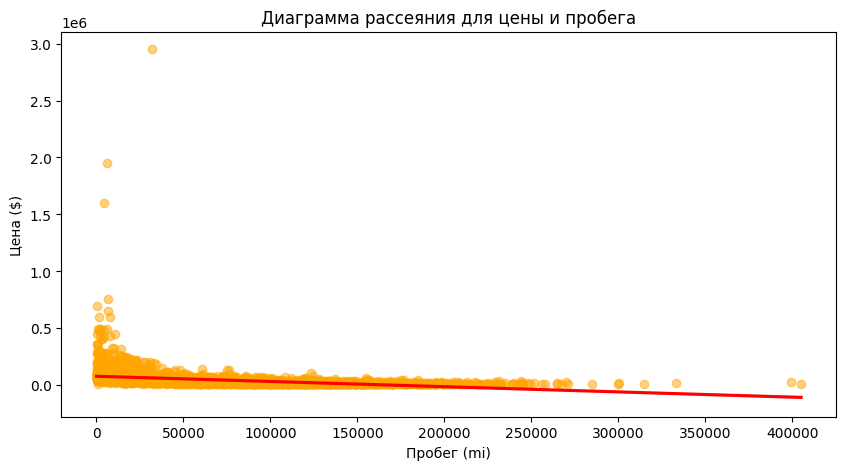

In [247]:
plt.figure(figsize=(10,5))
sns.regplot(data=df, x='milage', y='price', color='red', scatter_kws={'alpha': 0.5, 'color': 'orange'})
plt.title('Диаграмма рассеяния для цены и пробега')
plt.xlabel('Пробег (mi)')
plt.ylabel('Цена ($)')
plt.show()

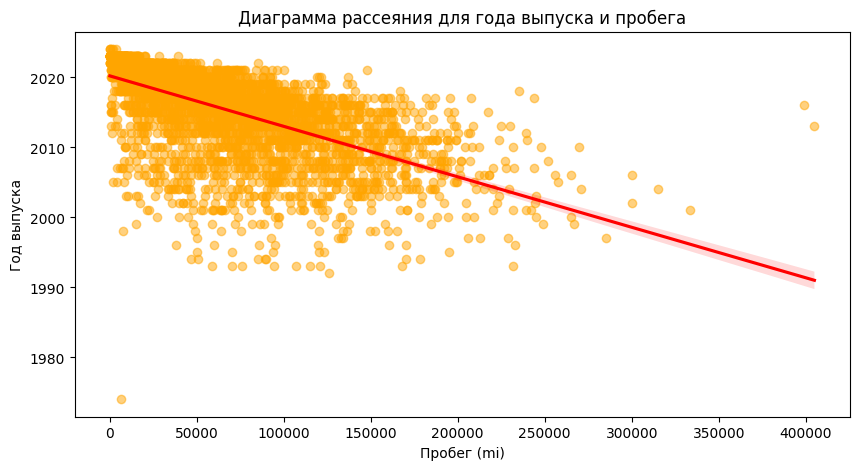

In [248]:
plt.figure(figsize=(10,5))
sns.regplot(data=df, x='milage', y='model_year', color='red', scatter_kws={'alpha': 0.5, 'color': 'orange'})
plt.title('Диаграмма рассеяния для года выпуска и пробега')
plt.xlabel('Пробег (mi)')
plt.ylabel('Год выпуска')
plt.show()

С графиком пробега/года производства всё ясно, есть отрицательная корреляция, ведь мы рассматриваем автомобили, которыми пользовались, а значит величина пробега постепенно возрастала.<br><br>
С диаграммой рассеяния для пробега и цены всё сложнее: прямая похожа на горизонтальную. Возможно, дело в выбросах.

### Диаграммы размаха

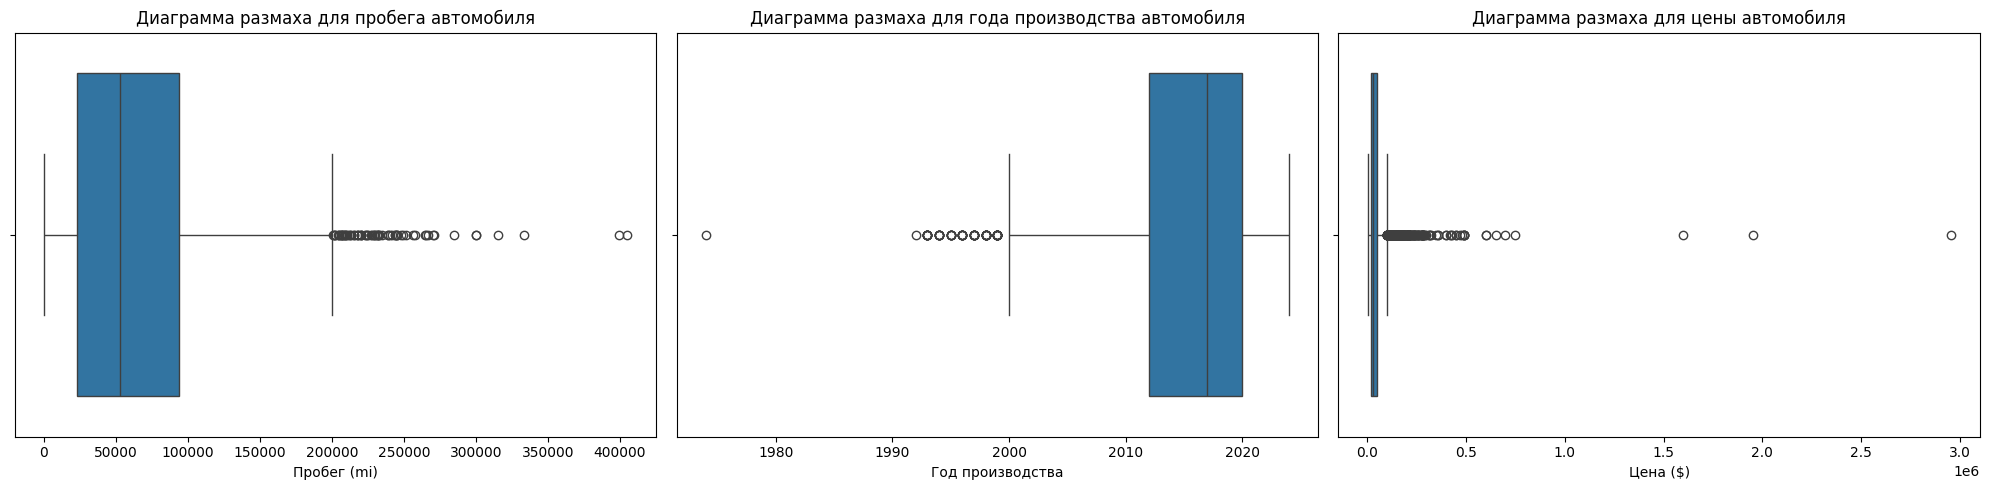

In [249]:
fig, axes = plt.subplots(1, 3, figsize=(20,5))
sns.boxplot(ax=axes[0], x=df['milage'])

axes[0].set_title('Диаграмма размаха для пробега автомобиля')
axes[0].set_xlabel('Пробег (mi)')

sns.boxplot(ax=axes[1], x=df['model_year'])
axes[1].set_title('Диаграмма размаха для года производства автомобиля')
axes[1].set_xlabel('Год производства')

sns.boxplot(ax=axes[2], x=df['price'])
axes[2].set_title('Диаграмма размаха для цены автомобиля')
axes[2].set_xlabel('Цена ($)')

plt.tight_layout()

Действительно, точки, которые слишком сильно выделяются на фоне остальных данных являются выбросами. Посмотрим на самые большие цены и величины пробега, а также на минимальные годы выпуска:

In [250]:
df[df['price'] > 1000000][['brand', 'model', 'model_year', 'milage', 'clean_title', 'price']]

,brand,model,model_year,milage,clean_title,price
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330,Yes,1950995
693,Maserati,Quattroporte Base,2005,32000,Yes,2954083
3046,Porsche,Carrera GT Base,2005,4400,Yes,1599000


In [251]:
df[df['model_year'] < 2000][['brand', 'model', 'model_year', 'milage', 'clean_title', 'price']]

,brand,model,model_year,milage,clean_title,price
163,Toyota,Land Cruiser Base,1997,213000,Yes,26500
167,Lexus,LX 470 Base,1999,82000,Yes,25000
257,Toyota,Land Cruiser Base,1993,231500,Yes,29500
387,Acura,Integra LS,1998,120000,Yes,5500
437,Mazda,MX-5 Miata Base,1999,96680,Yes,12900
...,...,...,...,...,...,...
3772,Jeep,Wrangler SE,1999,137790,Yes,12000
3882,Mazda,MX-5 Miata Base,1999,130000,Yes,9000
3918,Porsche,911 Carrera Cabriolet,1996,38000,NaN,75000
3922,Mazda,Protege DX,1993,94200,Yes,2500


In [252]:
df[df['milage'] > 250000][['brand', 'model', 'model_year', 'milage', 'clean_title', 'price']] 

,brand,model,model_year,milage,clean_title,price
31,Dodge,Ram 1500 Laramie Mega Cab,2006,300183,Yes,10900
499,Toyota,Highlander Hybrid Limited,2006,264893,Yes,5000
618,Volvo,S40 T5,2005,257700,Yes,3550
1145,GMC,Sierra 3500 SLE,2002,300000,Yes,5000
1876,Dodge,Dakota SLT Quad Cab,2006,256000,Yes,4000
2175,Ford,Excursion Limited,2001,333361,Yes,17000
2485,Dodge,Challenger SRT8,2008,251634,Yes,10500
2558,Toyota,Land Cruiser Base,2010,269885,Yes,22500
2764,Honda,Accord Sport,2013,405000,Yes,6000
3118,Dodge,Dakota Sport,1997,285000,Yes,6399


С очень высоким показателем цены выделяются авто с чистым ПТС и малым пробегом: Bugatti, Maserati, Porsche, также анализу будут мешать выделяющиеся по пробегу и году производства. Удалим их из датасета.

In [253]:
df = df[
    (df['price'] < 1000000) &
    (df['model_year'] >= 2000) &
    (df['milage'] <= 250000)
]

Изобразим тот же график рассеяния, только с более чистыми данными:

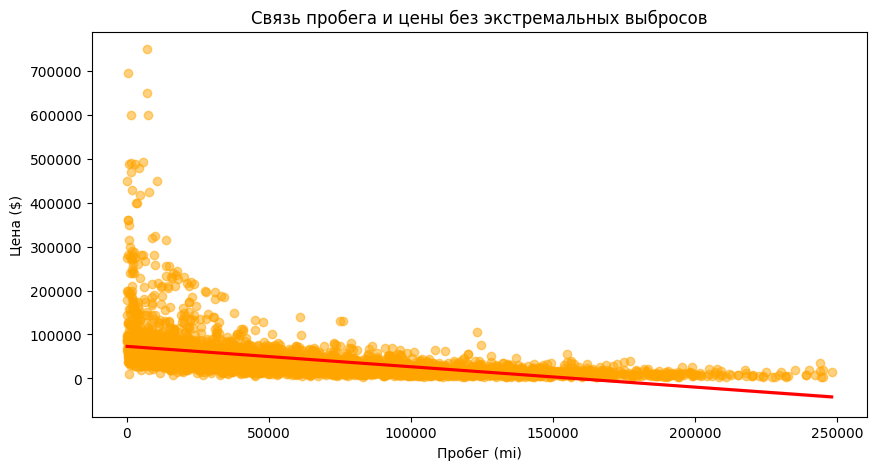

In [254]:
plt.figure(figsize=(10,5))
sns.regplot(data=df, x='milage', y='price', color='red', scatter_kws={'alpha': 0.5, 'color': 'orange'})
plt.xlabel('Пробег (mi)')
plt.ylabel('Цена ($)')
plt.title('Связь пробега и цены без экстремальных выбросов')
plt.show()

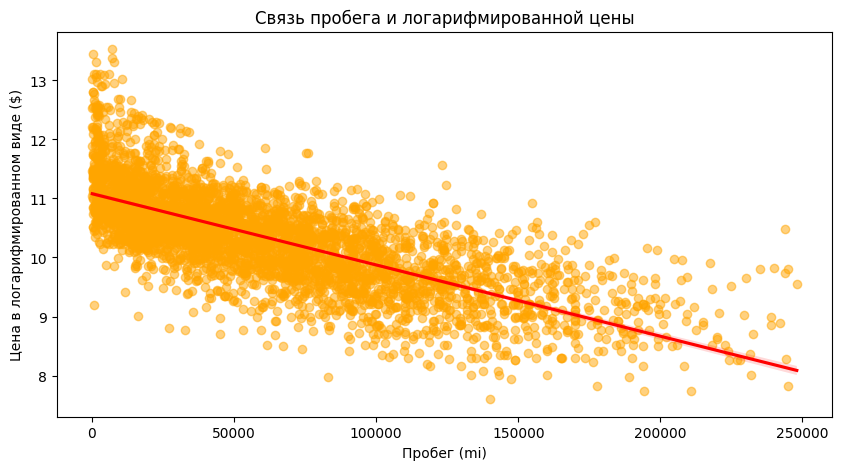

In [255]:
df['log_prices'] = np.log1p(df['price'])

plt.figure(figsize=(10,5))
sns.regplot(data=df, x='milage', y='log_prices', color='red', scatter_kws={'alpha': 0.5, 'color': 'orange'})
plt.title('Связь пробега и логарифмированной цены')
plt.xlabel('Пробег (mi)')
plt.ylabel('Цена в логарифмированном виде ($)')
plt.show()

При логарифмировании цены прослеживается более сильный наклон линии тренда, на график сверху (который без логарифмирования) действует некоторое количество выбросов, которые поднимают правую часть прямой, из-за этого она больше похожа на горизонтальную, однако всё равно зависимость присутствует, **гипотеза №1 об отрицательной корреляции цены и пробега подтвердилась**.

### Анализ уникальных значений признаков
Посмотрим на остальные признаки. Проанализируем уникальные значения в каждом из них.

In [256]:
for column in df.columns:
    print(f'Столбец {column}', end='\n\n')
    print(df[column].unique(), f'\nКоличество уникальных значений = {len(df[column].unique())}', sep='\n')
    print('------------------------------------------------------------------------------')

Столбец brand

['Ford' 'Hyundai' 'Lexus' 'INFINITI' 'Audi' 'Acura' 'BMW' 'Tesla' 'Land'
 'Aston' 'Toyota' 'Lincoln' 'Jaguar' 'Mercedes-Benz' 'Dodge' 'Nissan'
 'Genesis' 'Chevrolet' 'Kia' 'Jeep' 'Bentley' 'Honda' 'Lucid' 'MINI'
 'Porsche' 'Hummer' 'Chrysler' 'Volvo' 'Cadillac' 'Lamborghini' 'Maserati'
 'Volkswagen' 'Subaru' 'Rivian' 'GMC' 'RAM' 'Alfa' 'Ferrari' 'Scion'
 'Mitsubishi' 'Mazda' 'Saturn' 'Polestar' 'Rolls-Royce' 'McLaren' 'Buick'
 'Lotus' 'FIAT' 'Karma' 'Saab' 'Mercury' 'Pontiac' 'Plymouth' 'smart'
 'Maybach' 'Suzuki']

Количество уникальных значений = 56
------------------------------------------------------------------------------
Столбец model

['Utility Police Interceptor Base' 'Palisade SEL' 'RX 350 RX 350' ...
 'Martin DB7 Vantage Volante' 'Impala 2LZ' 'Taycan']

Количество уникальных значений = 1862
------------------------------------------------------------------------------
Столбец model_year

[2013 2021 2022 2015 2016 2017 2001 2020 2019 2003 2018 2023 2000 2011
 

### Удаление признаков

Какие-то признаки можно убрать. Они могут запутать модель из-за количества уникальных значений и отсутствия полезной информации.<br><br>Идём снизу вверх:
* Убираем `int_col` и `ext_col`. Цвета интерьера и кузова не дадут нам нужной пользы, их очень много, и цвет на б/у авто влияет минимально.
* Убираем `transmission`: здесь очень грязные данные, которые тяжело извлекать. Лучше от него избавиться.
* Убираем `model`: очень много уникальных значений, которые дают много шума.


In [257]:
df = df.drop(columns=['int_col', 'ext_col', 'transmission', 'model', 'log_prices'])
df.head()

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price
0,Ford,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,At least 1 accident or damage reported,Yes,10300
1,Hyundai,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,At least 1 accident or damage reported,Yes,38005
2,Lexus,2022,22372,Gasoline,3.5 Liter DOHC,None reported,NaN,54598
3,INFINITI,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,None reported,Yes,15500
4,Audi,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,None reported,NaN,34999


Что ещё можно заметить:
* `log_prices` убираем, рассмотрим поведение на логарифмической шкале позже.
* `clean_title` будем кодировать как 0 и 1 для *NaN* и *Yes* соответственно.
* `accident` тоже можно закодировать, но нужно учитывать пропущенные данные.

### Кодирование бинарных признаков и устранение пропусков

In [258]:
acc_col = len(df['accident'])
acc_nan = df['accident'].isna().sum()
acc_false = len(df[df['accident'] == 'None reported'])
acc_true = acc_col - acc_nan - acc_false
print(f'Количество значений: {acc_col}\n Количество NaN: {acc_nan}\n Количество авто без ДТП: {acc_false} \n Количество авто с ДТП: {acc_true}')

Количество значений: 3926
 Количество NaN: 110
 Количество авто без ДТП: 2857 
 Количество авто с ДТП: 959


Пропуски у `accident` можно заполнить модой. Так как признаков немало, и есть вероятность удалить важные данные, то смысла сносить такие объекты нет.

Пропуски у `clean_title` заполняем просто как No.

In [259]:
acc_mode = df['accident'].mode()

df['accident'] = df['accident'].fillna(acc_mode[0])

df['clean_title'] = df['clean_title'].fillna('No')

df.isna().sum()

brand            0
model_year       0
milage           0
fuel_type      170
engine           0
accident         0
clean_title      0
price            0
dtype: int64

Ещё раз посмотрим на `fuel_type`:

In [260]:
print(df['fuel_type'].unique())

['E85 Flex Fuel' 'Gasoline' 'Hybrid' nan 'Diesel' 'Plug-In Hybrid' '–'
 'not supported']


Справедливо будет заполнить колонки: *-* (прочерк) и *not supported* на *NaN*.

In [261]:
df['fuel_type'] = df['fuel_type'].replace(['–', 'not supported'], np.nan)
print('Теперь значений пропусков:', df['fuel_type'].isna().sum())

Теперь значений пропусков: 190


### Извлечение значений л.с. и объёмов двигателей

Попробуем теперь поработать с `engine`. Можно извлечь с помощью регулярного выражения данные о лошадиных силах и литраже двигателя и добавить 2 новые колонки.


In [262]:
df['horsepower'] = df['engine'].str.extract(r'(\d+\.?\d*)\s*HP').astype(float) # Берём числа, после которых идёт 'HP', числа с точкой тоже
df['engine_volume'] = df['engine'].str.extract(r'(\d+\.?\d*)\s*(?:L|Liter)').astype(float) # Здесь тоже берём числа, после которых идёт 'L' или 'Liter'

In [263]:
df.head()

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
0,Ford,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,At least 1 accident or damage reported,Yes,10300,300.0,3.7
1,Hyundai,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,At least 1 accident or damage reported,Yes,38005,NaN,3.8
2,Lexus,2022,22372,Gasoline,3.5 Liter DOHC,None reported,No,54598,NaN,3.5
3,INFINITI,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,None reported,Yes,15500,354.0,3.5
4,Audi,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,None reported,No,34999,NaN,2.0


In [264]:
print(f'Количество пропусков у лош. сил: {df['horsepower'].isna().sum()} из {len(df)}\n Количество пропусков у объёма двигателя: {df['engine_volume'].isna().sum()} из {len(df)}')

Количество пропусков у лош. сил: 779 из 3926
 Количество пропусков у объёма двигателя: 190 из 3926


Обратим внимание на модели с неизвестными значениями по типу топлива и объёму двигателя. Это могут быть электромобили.

In [265]:
potential_electro_mask = (df['engine_volume'].isna()) & (df['fuel_type'].isna())
df[potential_electro_mask]

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
9,Tesla,2020,34000,NaN,534.0HP Electric Motor Electric Fuel System,None reported,Yes,69950,534.0,NaN
44,Lucid,2022,3552,NaN,536.0HP Electric Motor Electric Fuel System,None reported,Yes,119999,536.0,NaN
68,Lucid,2022,4900,NaN,536.0HP Electric Motor Electric Fuel System,None reported,Yes,99000,536.0,NaN
92,Rivian,2023,2800,NaN,835.0HP Electric Motor Electric Fuel System,None reported,Yes,92000,835.0,NaN
122,Rivian,2023,2500,NaN,835.0HP Electric Motor Electric Fuel System,None reported,Yes,94000,835.0,NaN
...,...,...,...,...,...,...,...,...,...,...
3913,Tesla,2018,65000,NaN,518.0HP Electric Motor Electric Fuel System,None reported,Yes,41000,518.0,NaN
3932,Tesla,2020,25535,NaN,778.0HP Electric Motor Electric Fuel System,None reported,Yes,68969,778.0,NaN
3952,Dodge,2000,188000,NaN,–,At least 1 accident or damage reported,Yes,10000,NaN,NaN
3961,Tesla,2021,23749,NaN,Electric,None reported,No,35999,NaN,NaN


Это электроавтомобили. Это и логично, ведь у них нет типа топлива в привычном виде.

Займёмся ***явными электромобилями***, у них найдём слово *electric* в графе `engine`.

In [266]:
explicit_electro_mask = df['engine'].str.lower().str.contains('electric', na=False)
df[potential_electro_mask & explicit_electro_mask]

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
9,Tesla,2020,34000,NaN,534.0HP Electric Motor Electric Fuel System,None reported,Yes,69950,534.0,NaN
44,Lucid,2022,3552,NaN,536.0HP Electric Motor Electric Fuel System,None reported,Yes,119999,536.0,NaN
68,Lucid,2022,4900,NaN,536.0HP Electric Motor Electric Fuel System,None reported,Yes,99000,536.0,NaN
92,Rivian,2023,2800,NaN,835.0HP Electric Motor Electric Fuel System,None reported,Yes,92000,835.0,NaN
122,Rivian,2023,2500,NaN,835.0HP Electric Motor Electric Fuel System,None reported,Yes,94000,835.0,NaN
...,...,...,...,...,...,...,...,...,...,...
3908,Tesla,2021,49252,NaN,Electric,None reported,No,37999,NaN,NaN
3913,Tesla,2018,65000,NaN,518.0HP Electric Motor Electric Fuel System,None reported,Yes,41000,518.0,NaN
3932,Tesla,2020,25535,NaN,778.0HP Electric Motor Electric Fuel System,None reported,Yes,68969,778.0,NaN
3961,Tesla,2021,23749,NaN,Electric,None reported,No,35999,NaN,NaN


Их показатель объёма можно приравнивать к 0.0, а также создать новую категорию в `fuel_type`: *Electric*.
<br><br>Формально, "электрическое топливо" будет относиться к электрокарам, которые заряжают именно аккумуляторы, а не заполняют бак.


In [267]:
df.loc[potential_electro_mask & explicit_electro_mask, ['fuel_type', 'engine_volume']] = ['Electric', 0]

Остаточные модели, которые не содержат явного упоминания *electric*:

In [268]:
remains_mask = potential_electro_mask & ~explicit_electro_mask
df[remains_mask]

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
130,Chrysler,2017,87305,NaN,–,None reported,Yes,9000,NaN,NaN
338,Mazda,2016,85000,NaN,–,At least 1 accident or damage reported,Yes,18500,NaN,NaN
383,Ford,2023,923,NaN,Standard Range Battery,None reported,No,46998,NaN,NaN
456,Kia,2022,11945,NaN,111.2Ah / FR 70kW / RR 160kW (697V),None reported,No,38998,NaN,NaN
491,Chrysler,2017,63000,NaN,–,None reported,Yes,20000,NaN,NaN
555,Tesla,2022,3077,NaN,Dual Motor - Standard,None reported,No,44998,NaN,NaN
923,Dodge,2010,100100,NaN,–,None reported,Yes,17000,NaN,NaN
995,Dodge,2019,43000,NaN,–,None reported,Yes,50000,NaN,NaN
1063,Mazda,2016,83100,NaN,–,None reported,Yes,17800,NaN,NaN
1083,Dodge,2010,73000,NaN,–,None reported,Yes,17500,NaN,NaN


Здесь можно заполнить пропуски по объёму и типу топлива у автомобилей, у которых **указан двигатель**. Даже Dual Motor здесь смущать не должен, ибо он относится к Tesla - электромобилю.

Остальные авто (Dodge, GMC, Ford и т.д.) заполняем модой по `fuel_type` и медианой по `engine_volume`.


In [269]:
fuel_mode = df['fuel_type'].mode()[0]
engine_volume_median = df['engine_volume'].median()

df.loc[remains_mask & (df['engine'] == '–'), ['fuel_type', 'engine_volume']] = [fuel_mode, engine_volume_median]
df.loc[remains_mask & (df['engine'] != '–'), ['fuel_type', 'engine_volume']] = ['Electric', 0]
df[remains_mask]

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
130,Chrysler,2017,87305,Gasoline,–,None reported,Yes,9000,NaN,3.5
338,Mazda,2016,85000,Gasoline,–,At least 1 accident or damage reported,Yes,18500,NaN,3.5
383,Ford,2023,923,Electric,Standard Range Battery,None reported,No,46998,NaN,0.0
456,Kia,2022,11945,Electric,111.2Ah / FR 70kW / RR 160kW (697V),None reported,No,38998,NaN,0.0
491,Chrysler,2017,63000,Gasoline,–,None reported,Yes,20000,NaN,3.5
555,Tesla,2022,3077,Electric,Dual Motor - Standard,None reported,No,44998,NaN,0.0
923,Dodge,2010,100100,Gasoline,–,None reported,Yes,17000,NaN,3.5
995,Dodge,2019,43000,Gasoline,–,None reported,Yes,50000,NaN,3.5
1063,Mazda,2016,83100,Gasoline,–,None reported,Yes,17800,NaN,3.5
1083,Dodge,2010,73000,Gasoline,–,None reported,Yes,17500,NaN,3.5


In [270]:
empty_vol_anomaly_mask = df['engine_volume'].isna() & ~(df['fuel_type'].isna())
df[empty_vol_anomaly_mask]

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
10,Land,2021,27608,Gasoline,V6,None reported,No,73897,NaN,NaN
32,BMW,2020,35035,Hybrid,120 AH,None reported,No,24998,NaN,NaN
120,Land,2018,104700,Gasoline,V6,At least 1 accident or damage reported,No,30775,NaN,NaN
686,Land,2020,59355,Gasoline,V8,None reported,Yes,72995,NaN,NaN
2213,Bentley,2022,1919,Gasoline,12 Cylinder Engine,None reported,No,289991,NaN,NaN
2348,BMW,2016,91798,Hybrid,Electric,None reported,No,22998,NaN,NaN
2801,Land,2023,12425,Gasoline,I4,None reported,No,57619,NaN,NaN


Заполняем медианой оставшиеся выделившиеся строки с неизвестным `engine_volume`:

In [271]:
df.loc[empty_vol_anomaly_mask, ['engine_volume']] = engine_volume_median
df[empty_vol_anomaly_mask]

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
10,Land,2021,27608,Gasoline,V6,None reported,No,73897,NaN,3.5
32,BMW,2020,35035,Hybrid,120 AH,None reported,No,24998,NaN,3.5
120,Land,2018,104700,Gasoline,V6,At least 1 accident or damage reported,No,30775,NaN,3.5
686,Land,2020,59355,Gasoline,V8,None reported,Yes,72995,NaN,3.5
2213,Bentley,2022,1919,Gasoline,12 Cylinder Engine,None reported,No,289991,NaN,3.5
2348,BMW,2016,91798,Hybrid,Electric,None reported,No,22998,NaN,3.5
2801,Land,2023,12425,Gasoline,I4,None reported,No,57619,NaN,3.5


Оценим оставшиеся данные:

In [272]:
df.isna().sum()
df[df['fuel_type'].isna()]

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
719,Karma,2018,21000,NaN,403.0HP 2.0L Electric Motor Electric Fuel System,None reported,Yes,51000,403.0,2.00
1098,BMW,2014,29553,NaN,170.0HP 0.65L Electric Motor Electric Fuel System,None reported,Yes,12800,170.0,0.65
1554,Karma,2018,20760,NaN,403.0HP 2.0L Electric Motor Electric Fuel System,None reported,Yes,55500,403.0,2.00
3090,BMW,2019,16975,NaN,170.0HP 0.65L Electric Motor Electric Fuel System,None reported,Yes,26990,170.0,0.65
3255,BMW,2015,26000,NaN,170.0HP 0.65L Electric Motor Electric Fuel System,None reported,Yes,14999,170.0,0.65
3324,BMW,2014,74500,NaN,170.0HP 0.65L Electric Motor Electric Fuel System,None reported,Yes,11499,170.0,0.65
3468,BMW,2017,43000,NaN,170.0HP 0.65L Electric Motor Electric Fuel System,None reported,Yes,16500,170.0,0.65


Остались гибридные авто с очень малым объёмом двигателя, заполним их типы как гибридные. 

In [273]:
df['fuel_type'] = df['fuel_type'].fillna('Hybrid')
df.isna().sum()

brand              0
model_year         0
milage             0
fuel_type          0
engine             0
accident           0
clean_title        0
price              0
horsepower       779
engine_volume      0
dtype: int64

### Заполнение пропусков с помощью группировки

Остались пропуски по лошадиным силам. Попробуем заполнить их, сгруппировав значения по каждому бренду авто. 

То есть мы берём медиану лошадиных сил у каждого бренда по отдельности и заполняем ей пропуски у авто соответствующих марок.

In [274]:
df['horsepower'] = df['horsepower'].fillna(df.groupby('brand')['horsepower'].transform('median'))

In [275]:
df[df['horsepower'].isna()]

,brand,model_year,milage,fuel_type,engine,accident,clean_title,price,horsepower,engine_volume
236,Polestar,2021,12172,Electric,Electric,None reported,No,35999,NaN,0.0


In [276]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

In [277]:
df.isna().sum()

brand            0
model_year       0
milage           0
fuel_type        0
engine           0
accident         0
clean_title      0
price            0
horsepower       0
engine_volume    0
dtype: int64

Включим в датасет колонку с возрастом автомобиля - `car_age`. Также уберём столбец `engine`, ведь всю необходимую информацию уже извлекли. 

In [278]:
df['car_age'] = datetime.now().year - df['model_year']
df = df.drop('engine', axis=1)

### Кодирование бинарных признаков

Построим матрицу корреляций и изобразим тепловую карту на основе временного датасета `df_eda`. Закодируем бинарные категориальные признаки с помощью `get_dummies`:

In [279]:
df_eda = pd.get_dummies(df, columns=['accident', 'clean_title'], drop_first=True)
df_eda.head()

,brand,model_year,milage,fuel_type,price,horsepower,engine_volume,car_age,accident_None reported,clean_title_Yes
0,Ford,2013,51000,E85 Flex Fuel,10300,300.0,3.7,13,False,True
1,Hyundai,2021,34742,Gasoline,38005,240.0,3.8,5,False,True
2,Lexus,2022,22372,Gasoline,54598,301.0,3.5,4,True,False
3,INFINITI,2015,88900,Hybrid,15500,354.0,3.5,11,True,True
4,Audi,2021,9835,Gasoline,34999,333.0,2.0,5,True,False


### Матрица корреляций и тепловая карта

Матрицу будем строить на основе числовых и двух бинарных признаков, уберём лишние данные из временного датасета и **изобразим тепловую карту**: 

In [280]:
df_eda = df_eda.drop(columns=['brand', 'fuel_type'])

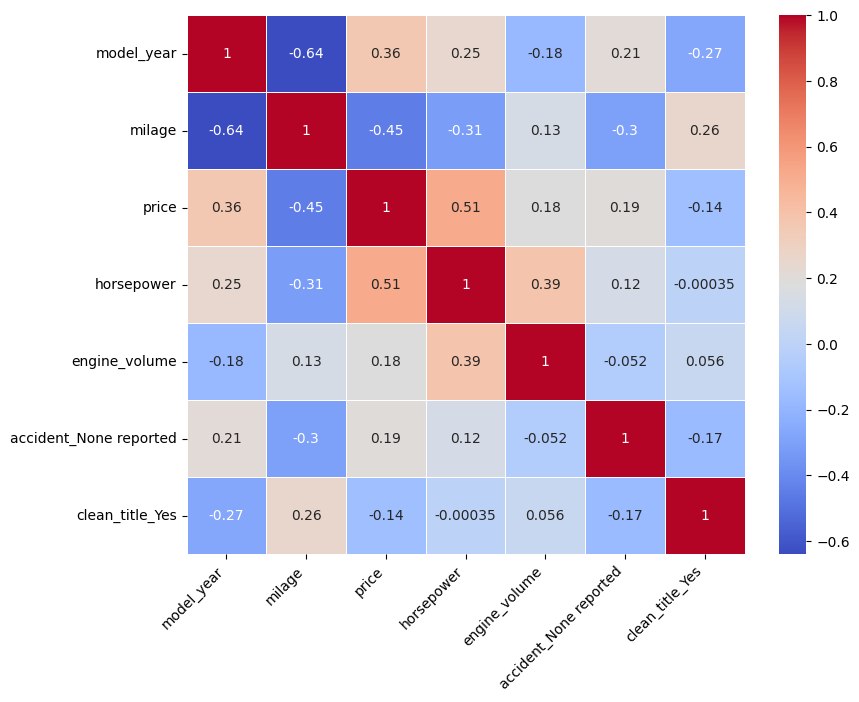

In [281]:
corr_matrix = df_eda.drop('car_age', axis=1).corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.xticks(rotation=45, ha='right')
plt.show()

По тепловой карте можно заметить, что у цены и чистого ПТС вообще отрицательная корреляция, хоть и по модулю небольшая. Значит, **гипотеза №2** о положительной корреляции чистого ПТС и цены **не подтвердилась**.

## Подготовка данных

Выделим 15 самых популярных брендов, остальные оставим как *Other*. От марки авто может зависеть цена, так как например BMW и Nissan с одими и теми же характеристиками будут стоить по-разному.

In [282]:
top_15 = df['brand'].value_counts().index[:15]
df['brand'] = df['brand'].apply(lambda x: x if x in top_15 else 'Other')
df['brand'].unique()

array(['Ford', 'Other', 'Lexus', 'Audi', 'BMW', 'Tesla', 'Land', 'Toyota',
       'Mercedes-Benz', 'Nissan', 'Chevrolet', 'Jeep', 'Porsche',
       'Cadillac', 'GMC', 'RAM'], dtype=object)

### Распределение на тренировочные и тестовые данные

Таблицу с признаками объявляем как `Х`, таргет в `у`:

In [283]:
X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=52)

In [284]:
df.head()

,brand,model_year,milage,fuel_type,accident,clean_title,price,horsepower,engine_volume,car_age
0,Ford,2013,51000,E85 Flex Fuel,At least 1 accident or damage reported,Yes,10300,300.0,3.7,13
1,Other,2021,34742,Gasoline,At least 1 accident or damage reported,Yes,38005,240.0,3.8,5
2,Lexus,2022,22372,Gasoline,None reported,No,54598,301.0,3.5,4
3,Other,2015,88900,Hybrid,None reported,Yes,15500,354.0,3.5,11
4,Audi,2021,9835,Gasoline,None reported,No,34999,333.0,2.0,5


Преобразуем категориальные признаки с помощью `OneHotEncoder`, масштабируем числовые с использованием `RobustScaler`, так как он более устойчив к выбросам.

In [285]:
num_cols_with_age = ['car_age', 'milage', 'horsepower', 'engine_volume']
num_cols_with_year = ['model_year', 'milage', 'horsepower', 'engine_volume']
cat_cols = ['accident', 'brand', 'fuel_type', 'clean_title']

In [286]:
preprocessor_with_age = ColumnTransformer([
    ('num', RobustScaler(), num_cols_with_age),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

preprocessor_with_year = ColumnTransformer([
    ('num', RobustScaler(), num_cols_with_year),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

## Обучение моделей

Создадим два пайплайна - с возрастом автомобиля и годом производства. Проведем кросс-валидацию и посчитаем среднее значение коэффициента детерминации на 5 фолдах. В качестве baseline возьмём сразу Ridge-регрессию:

In [287]:
pipe_with_age = Pipeline([
    ('prep', preprocessor_with_age),
    ('model', Ridge(alpha=1.0))
])

pipe_with_year = Pipeline([
    ('prep', preprocessor_with_year),
    ('model', Ridge(alpha=1.0))
])

score_with_age = cross_val_score(pipe_with_age, X_train, y_train, cv=5, scoring='r2').mean()
score_with_year = cross_val_score(pipe_with_year, X_train, y_train, cv=5, scoring='r2').mean()

print(f'Коэффициент детерминации R2 с использованием model_year: {score_with_year:.5f}')
print(f'Коэффициент детерминации R2 с использованием car_age:    {score_with_age:.5f}')

Коэффициент детерминации R2 с использованием model_year: 0.43102
Коэффициент детерминации R2 с использованием car_age:    0.43102


**Гипотеза №3 не подтвердилась**. Коэффициент детерминации точно такой же, начало отсчёта с 0 не повлияло на модель. Возможно, так происходит из-за линейности операции, ведь мы посчитали столбец с возрастом, отняв из текущего года год производства. Будем использовать год производства в дальнейшей работе.

Логарифмируем таргет, используем ту же модель:

In [288]:
X_train = X_train.drop('car_age', axis=1)
X_test = X_test.drop('car_age', axis=1)

In [289]:
pipe_log_target = Pipeline([
    ('prep', preprocessor_with_year),
    ('model', TransformedTargetRegressor(regressor=Ridge(alpha=1.0), func=np.log1p, inverse_func=np.expm1))
])

score_with_year_log = cross_val_score(pipe_log_target, X_train, y_train, cv=5, scoring='r2').mean()
print(f'Коэффициент детерминации R2 с логарифмированием таргета: {score_with_year_log:.5f}')

Коэффициент детерминации R2 с логарифмированием таргета: 0.50181


Логарифмирование таргета действительно улучшило показатель базовой Ridge модели, **гипотеза №4 подтвердилась**. Наличие серьёзных выбросов сказывается на точности модели, а логарифмирование таргета уменьшает влияние экстремальных значений.


Рассмотрим модель решающего дерева:

In [290]:
pipe_tree = Pipeline([
    ('prep', preprocessor_with_year),
    ('model', TransformedTargetRegressor(regressor=DecisionTreeRegressor(max_depth=7, random_state=52), func=np.log1p, inverse_func=np.expm1))
])

score_with_year_tree = cross_val_score(pipe_tree, X_train, y_train, cv=5, scoring='r2').mean()
print(f'Коэффициент детерминации R2 у решающего дерева: {score_with_year_tree:.5f}')

Коэффициент детерминации R2 у решающего дерева: 0.63163


### Подбор параметров на основе GridSearch

Выбираем в качестве лучшей модели решающее дерево и попробуем подобрать параметры:

In [291]:
param_grid = {
    'model__regressor__max_depth': range(4, 9),
    'model__regressor__min_samples_split': range(10, 51, 5),
    'model__regressor__min_samples_leaf': range(2, 25, 2),
    'model__regressor__max_features': [None, 0.5, 0.6, 0.7, 0.8]
}

In [292]:
grid_search = GridSearchCV(pipe_tree, param_grid, cv=5, scoring='r2', n_jobs=-1)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('num',
                                                                         RobustScaler(),
                                                                         ['model_year',
                                                                          'milage',
                                                                          'horsepower',
                                                                          'engine_volume']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['accident',
                                                                          'brand',
                                                                          'fuel_type',
                                                                          'clean_title'])])),
                                       ('model',
                                        TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                                                   inverse_func=<ufunc 'expm1'>,
                                                                   regressor=DecisionTreeRegressor(max_depth=7,
                                                                                                   random_state=52)))]),
             n_jobs=-1,
             param_grid={'model__regressor__max_depth': range(4, 9),
                         'model__regressor__max_features': [None, 0.5, 0.6, 0.7,
                                                            0.8],
                         'model__regressor__min_samples_leaf': range(2, 25, 2),
                         'model__regressor__min_samples_split': range(10, 51, 5)},
             scoring='r2')

In [293]:
print(f'Лучшие параметры:')

for param, value in grid_search.best_params_.items():
    print(f'{param.replace('model__regressor__', '')}: {value}')

print(f'\nЛучший показатель R2 на решающем дереве: {grid_search.best_score_:.5f}')

Лучшие параметры:
max_depth: 8
max_features: 0.8
min_samples_leaf: 4
min_samples_split: 20

Лучший показатель R2 на решающем дереве: 0.73805


Проверим итоговую модель на тестовой выборке и посмотрим на другие метрики: средняя абсолютная ошибка и корень из среднеквадратической ошибки. 

In [294]:
y_test_pred = grid_search.best_estimator_.predict(X_test)
r2 = r2_score(y_test, y_test_pred)
mae = mean_absolute_error(y_test, y_test_pred)
rmse = mean_squared_error(y_test, y_test_pred)**0.5

print(
    f'Коэффициент детерминации R2: {r2:.5f}\nMean absolute error (MAE): {mae:.5f}\nRoot of mean squared error (RMSE): {rmse:.5f}\n'
)

Коэффициент детерминации R2: 0.61983
Mean absolute error (MAE): 12745.41985
Root of mean squared error (RMSE): 31637.35062



По сравнению с тренировочными данными модель решающего дерева немного переобучилась, коэффициент детерминации стал ниже. Возможно, это из-за самой структуры деревьев и её усложнения на каждом этапе, так как деревья стараются подстроиться под каждый автомобиль.<br><br>
Однако GridSearch действительно нашёл лучшие параметры, из-за чего коэффициент детерминации вырос, и **гипотеза №5 подтвердилась**.<br><br>

У таргета (цены) есть изменчивость, а его оценка происходит на основе признаков автомобилей. 
Коэффициент детерминации `R2 = 0.62` на итоговом тесте говорит о доле этой изменчивости, которую модель смогла объяснить.

Средняя абсолютная ошибка со значением `MAE = 12745.4` выражается в тех же единицах, что и цена ($) и показывает среднее число, на которое отклоняется предсказание от идеального.
<br><br>
Корень из среднеквадратической ошибки `MSE = 31637.4`тоже выражается в тех же единицах, только явно показывает, как модель ошибается на выбросах или экстремальных значениях цен. Этот показатель превышает среднюю абсолютную ошибку в несколько раз, значит модель испытывает сложности с прогнозированием на редкие авто.

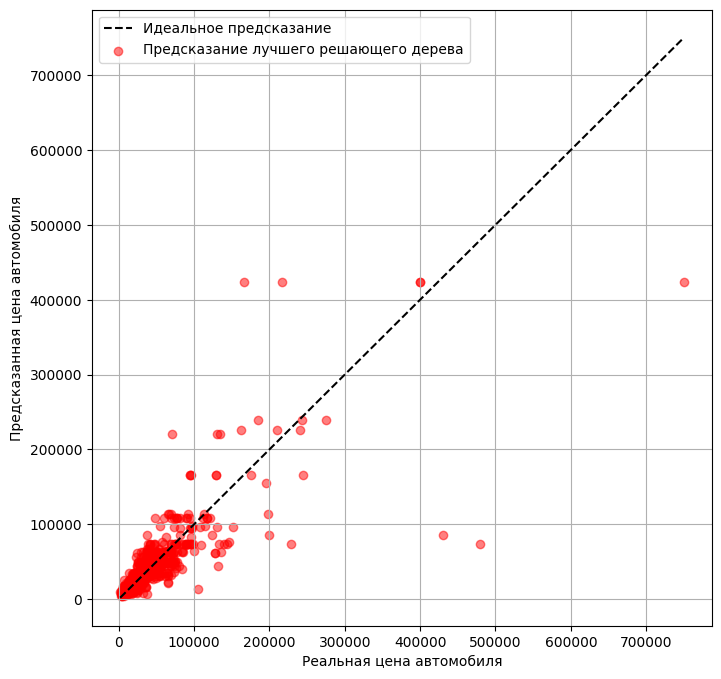

In [295]:
plt.figure(figsize=(8,8))

perfect = np.linspace(min(y_test), max(y_test), 100)

plt.plot(perfect, perfect, color='black', linestyle='--', label='Идеальное предсказание')
plt.scatter(y_test, y_test_pred, alpha=0.5, color='red', label='Предсказание лучшего решающего дерева')
plt.legend()
plt.xlabel('Реальная цена автомобиля')
plt.ylabel('Предсказанная цена автомобиля')
plt.grid(True)
plt.show()

Действительно, даже лучшее по параметрам решающее дерево плохо справляется с критическими выбросами.

### Важность признаков

Для начала нужно достать признаки и их важность из объекта `Pipeline`, затем собрать датафрейм из признаков и относительной важности для лучшего решающего дерева.

In [296]:
feature_names = grid_search.best_estimator_.named_steps['prep'].get_feature_names_out()

best_decision_tree = grid_search.best_estimator_.named_steps['model'].regressor_

feature_importances = best_decision_tree.feature_importances_

imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

imp_df['Feature'] = imp_df['Feature'].str.replace('num__', '', regex=False).str.replace('cat__', '', regex=False)

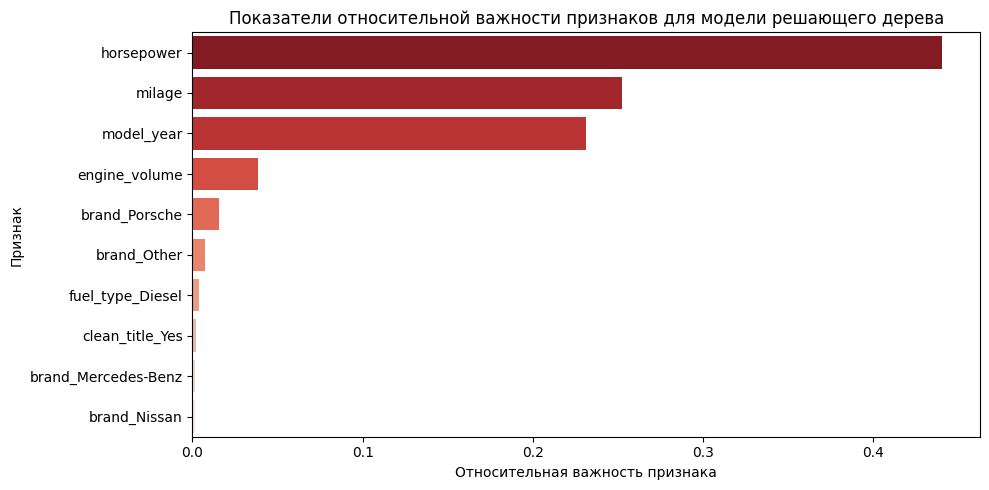

In [297]:
plt.figure(figsize=(10,5))
sns.barplot(data=imp_df.head(10), x='Importance', y='Feature', palette='Reds_r', hue='Feature')
plt.title('Показатели относительной важности признаков для модели решающего дерева')
plt.xlabel('Относительная важность признака')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

Самыми важными признаками оказались `horsepower`, `milage` и `model_year`. Извлечение лошадиных сил из столбца `engine` было верным решением. Лучшее по метрикам решающее дерево также учитывает объём двигателя и наличие бренда *Porsche*. Вероятно, у таких автомобилей отличительные показатели в описании двигателя и цене, поэтому такие автомобили выделяются. Стоит также выделить наличие чистого ПТС - здесь он совсем не влияет на цену автомобиля для этой модели. Наличие ДТП в истории автомобиля тоже не оказывает никакого влияния на целевую переменную.